# Introduction to Data Science and Systems 2026-2027
## Lab 3 (Week 5): Optimisation 
#### 
---
#### MSc Data Science, University of Glasgow


## What this lab is for

This lab notebook is for you to apply in practice some of the optimisation concepts seen in class. 

It should take about **30 minutes**. **Lab 3 will count towards your course grade.**

## How the labs work (reminder)

* Questions are labelled **Task N**. Each one has an **answer cell** that starts out containing

      # YOUR CODE HERE
      raise NotImplementedError()

  Replace **both** of those lines with your answer. **Only edit cells that contain
  `# YOUR CODE HERE`** - changing anything else can corrupt the notebook and cost you marks.

* Note: Do not import additional python packages in your answers. The labs will never require it, 
and it will be penalised. 

* After a task there are one or more **test cells** (you cannot edit these). Run them to check your
  answer:
  * a green **&check; [n marks]** box means the test passed;
  * a red **&cross; Test failed** box means it did not.

* Some tests are **hidden**. Running a hidden test cell shows *nothing* now; it is only scored later.
  So "no output" from a test cell is normal and does **not** mean something is wrong.

* Before you finish, always use **Kernel &rarr; Restart Kernel and Run All Cells**, then check the
  marks summary at the bottom.

* When finished, submit your notebook to Moodle for marking. **Make sure to submit your work before the end of the session!**


Now import the packages the autograder needs. **Make sure you run this cell.**


In [1]:
## Standard imports -- run this cell!
from __future__ import print_function, division
import os

# course grading utilities
%pip install scikit-image
%pip install -U --force-reinstall --no-cache https://github.com/pugeault/jhwutils/zipball/master
from jhwutils.checkarr import array_hash, check_hash, check_string
import jhwutils.tick as tick

# numpy and plotting 
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

version_id = "v20262027a"

# reset the visible marks counter
tick.reset_marks()

print("Everything imported OK")


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for jhwutils: filename=jhwutils-1.4.0-py3-none-any.whl size=46870 sha256=f421a18c213a9b8db6c5ca4fa2588bb42eb1baea1d233ead08c2aac6009ab819
  Stored in directory: C:\Users\3188758P\AppData\Local\Temp\pip-ephem-wheel-cache-vniv_3lt\wheels\4d\0d\ce\7741fa18c491f96ea9c5eccb7b787d7264de88ca395518d1be
Successfully built jhwutils
  Attempting uninstall: jhwutils
    Found existing installation: jhwutils 1.4.0
    Uninstalling jhwutils-1

In [2]:
# This cell is used for grading purposes. Do not modify it.



---
## Task 0 &mdash; Tell us who you are

Set the two variables below:

* `student_id` &mdash; your 8-character student ID (for example `"1234567s"`).
* `student_typewritten_signature` &mdash; your full name, for example `"Ada Lovelace"`. Typing your
  name is your declaration that this notebook is your own work.

This is your first answer cell: replace the `# YOUR CODE HERE` / `raise NotImplementedError()` lines
with your answer, then run the test cell that follows.


In [3]:
student_id = "3188758p"                     # your 8-char student id, e.g. "1234567s"
student_typewritten_signature = "Subhranshu Panda"  # your full name, e.g. "Ada Lovelace"



In [4]:

with tick.marks(0):  # no credit for knowing your own id -- this is just a format check
    assert len(student_id) == 8

with tick.marks(0):
    assert len(student_typewritten_signature) > 0



---
# Part 1 Line fitting


## Task 1 &mdash; Fitting a line &nbsp;*(1 mark)*

You have recorded a dataset that is a collection of $(x,y)$ pairs. When plotting the data you get the following graph:




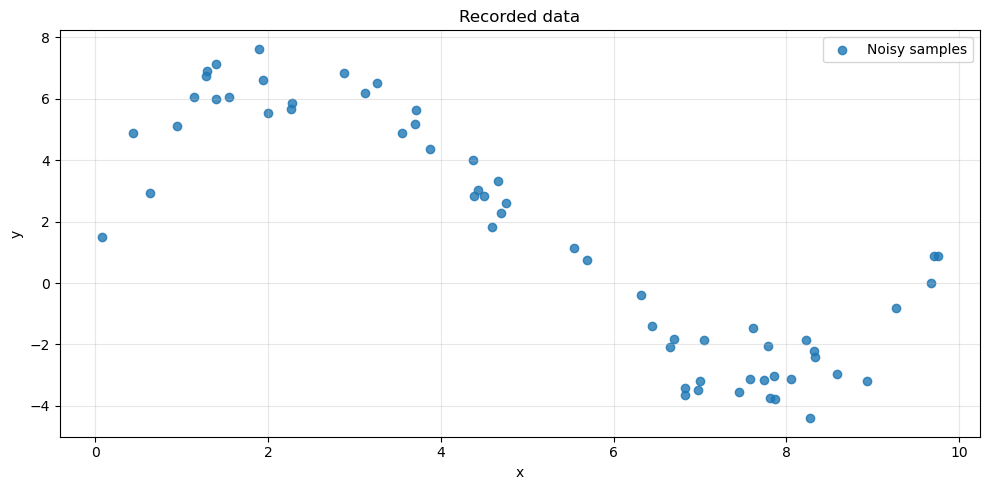

In [5]:

x = np.array([0.0736227 , 0.43803766, 0.63817256, 0.94177348, 1.14530074,
       1.28113633, 1.29921505, 1.39752484, 1.39796998, 1.54289492,
       1.89471359, 1.94638708, 1.99908202, 2.26909349, 2.27238722,
       2.88328104, 3.12366641, 3.25825358, 3.54525968, 3.70459706,
       3.70798024, 3.87478379, 4.37151919, 4.3887844 , 4.43414199,
       4.50385938, 4.58915776, 4.66721004, 4.69555811, 4.75704926,
       5.54584787, 5.68741196, 6.31664399, 6.4386512 , 6.64850857,
       6.69813995, 6.82495504, 6.83048953, 6.97368029, 7.00265102,
       7.05165379, 7.44762156, 7.5808774 , 7.61139702, 7.73956049,
       7.78383497, 7.80729031, 7.86064305, 7.86924378, 8.04764357,
       8.22761613, 8.27631172, 8.32259801, 8.32678196, 8.5859792 ,
       8.93121121, 9.26764989, 9.67509732, 9.70698024, 9.75622352])
y = np.array([ 1.49419183e+00,  4.87905609e+00,  2.92308719e+00,  5.12710584e+00,
        6.07191676e+00,  6.74021276e+00,  6.89466449e+00,  7.12430509e+00,
        5.98285281e+00,  6.04862566e+00,  7.62682518e+00,  6.59537077e+00,
        5.52412932e+00,  5.65730985e+00,  5.87027081e+00,  6.84056239e+00,
        6.17267250e+00,  6.51646117e+00,  4.90173591e+00,  5.17966952e+00,
        5.63996098e+00,  4.36122906e+00,  4.00315302e+00,  2.84327900e+00,
        3.03347268e+00,  2.84640088e+00,  1.82433130e+00,  3.31526177e+00,
        2.28888066e+00,  2.61843694e+00,  1.13239052e+00,  7.60483912e-01,
       -3.97977866e-01, -1.39735336e+00, -2.09657425e+00, -1.83537898e+00,
       -3.64192789e+00, -3.40999565e+00, -3.48807018e+00, -3.20068894e+00,
       -1.86576105e+00, -3.55819927e+00, -3.11125216e+00, -1.44844963e+00,
       -3.14907254e+00, -2.06467293e+00, -3.73945196e+00, -3.01610126e+00,
       -3.76100938e+00, -3.12745063e+00, -1.86636118e+00, -4.40123514e+00,
       -2.20403696e+00, -2.39731061e+00, -2.94779879e+00, -3.19862634e+00,
       -8.24394644e-01,  9.06806163e-04,  8.93852413e-01,  8.90661498e-01])
plt.figure(figsize=(10, 5))
plt.scatter(x, y, color='C0', alpha=0.8, label="Noisy samples")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Recorded data")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.show()

You want to approximate the relation $y = f(x)$ by a line. 

The definition of a line, this means $y = a x + b$, where each pair of values of $(a,b)$ describe a different line in the plane – and every line can be described by a pair of $(a,b)$ values. 

Try to set values of $(a,b)$ such that your line below fits reasonably well the points

In [6]:
a = -1.0 # change those values to fit the line to the points 
b = 7.0


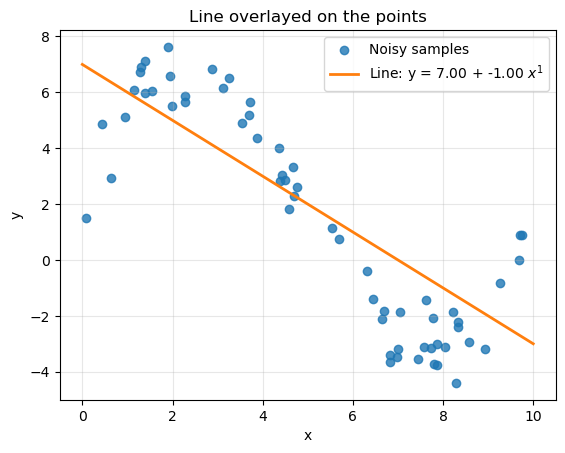

In [7]:
# we define our linear model
def linear_model(x, theta): 
    assert(len(theta)==2)
    return theta[1]*x + theta[0]

def model_equation(theta): 
    s = "y = "
    for i in range(len(theta)):
        if i == 0:
            s += f"{float(theta[i]):.2f}"
        else:
            s += f" + {float(theta[i]):.2f} $x^{i}$"

    return s

# This cell will show your line overlapping the points
def plot_line(theta, ax=plt.gca(), model=linear_model, label="Line", color='C1', samples=True): 
    x_line = np.linspace(0, 10, 500)
    y_line = model(x_line, theta)
    
    if samples: 
        ax.scatter(x, y, color='C0', alpha=0.8, label="Noisy samples")
    ax.plot(x_line, y_line, color, lw=2, label=f"{label}: {model_equation(theta)}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title("Line overlayed on the points")
    ax.legend()
    ax.grid(alpha=0.3)

plot_line([b, a])

You should be able to assert the correctness of the fit visually.

In [8]:
with tick.marks(1):
    error = sum( abs(y - (a*x+b)) ) / len(x)
    print(error)
    assert(error < 2.0)

1.7753918571193836


## Task 2 &mdash; Defining a loss function &nbsp;*(2 marks: 1 mark with feedback, 1 hidden test)*

Fitting a model $f(x; \theta)$ (in our case a line) to a set of noisy data $\mathbf{x}, \mathbf{y}$ is a standard problem. 

In order to resolve it using optimisation, we need to define a *loss function* $L(\mathbf{x},\mathbf{y}; \theta)$, such that parameter values $\theta = (\theta_0 = a, \theta_1 = b)$ for good models $f(x;\theta)$ that fits the data better yield a lower loss than parameter values for worse models. 

A common loss for this task is the mean squared error (MSE), that is written as
$$
L(\mathbf{x},\mathbf{y}; \theta) = \frac{1}{N}\sum_{i=1}^{N} (y_i - f(x_i; \theta))^2 
$$
for $N$ data points $(x_i, y_i)$.

**Task:** Complete the loss function definition below so that it returns the MSE loss for our linear model. 

In [9]:
def mse_loss(y_true, y_pred): 
    return np.mean((y_true - y_pred) ** 2)

We can then use this to calculate the fit of the line you defined earlier: 

In [10]:
print( f"The MSE loss of the line y={a}x+{b} is {mse_loss(y, a*x+b)}" )

The MSE loss of the line y=-1.0x+7.0 is 4.479900348695139


In [11]:
# This cell will do some tests for 1 mark
with tick.marks(1):
    assert( mse_loss( y, y ) < 1e-5 )
    assert( abs(mse_loss( y, y + 1.0 ) - 1.0) < 1e-5 )
    assert( mse_loss( y, -x + 1.0 ) - mse_loss( y, x + 1.0 ) < 0 )


In [12]:
# This cell will do some additional hidden tests for 1 mark



## Task 3 &mdash; Grid Search &nbsp;*(3 marks with feedback)*

We want to find a good set of parameters for our line model that fits the available data minimising the mse loss. 

First, we will try the grid search algorithm, this works as follows: 

- split the range of possible values for each parameters in a regular grid of N values (we need sensible minimum and maximum values)
- test exhaustively all combination of parameter values $\theta'$
- check if $L(\mathbf{x},\mathbf{y},\theta') < L(\mathbf{x},\mathbf{y},\theta)$, where $\theta$ is the current best parameter set.  
- if yes, replace $\theta$ with $\theta'$
- return the best set of parameters once all possible parameter values have been tested. 

Below you are asked to implement the code for each iteration of the algorithm. 

In [13]:
def grid_search(x, y, model, loss, steps): 
    theta = None
    best_loss = np.inf
    history = []
    for a in np.linspace(-10, +10, steps):
        for b in np.linspace(-10, +10, steps):
            candidate_theta = np.array([a, b])
            candidate_loss = loss(y, model(x, candidate_theta))

            if candidate_loss < best_loss:
                theta = candidate_theta
                best_loss = candidate_loss
            history.append((theta, best_loss))
    return theta, best_loss, history

You can then run the cell below to run your grid search and display the result of the optimisation

In [14]:
# This cell will do some basic tests on your function for 1 mark
np.random.seed(42)
theta, best_loss, history_gs = grid_search(x,y, linear_model, mse_loss, 10)
with tick.marks(1):
    for i in range(len(history_gs)-1):
        assert history_gs[i][1] >= history_gs[i+1][1] # check that the loss is decreasing 

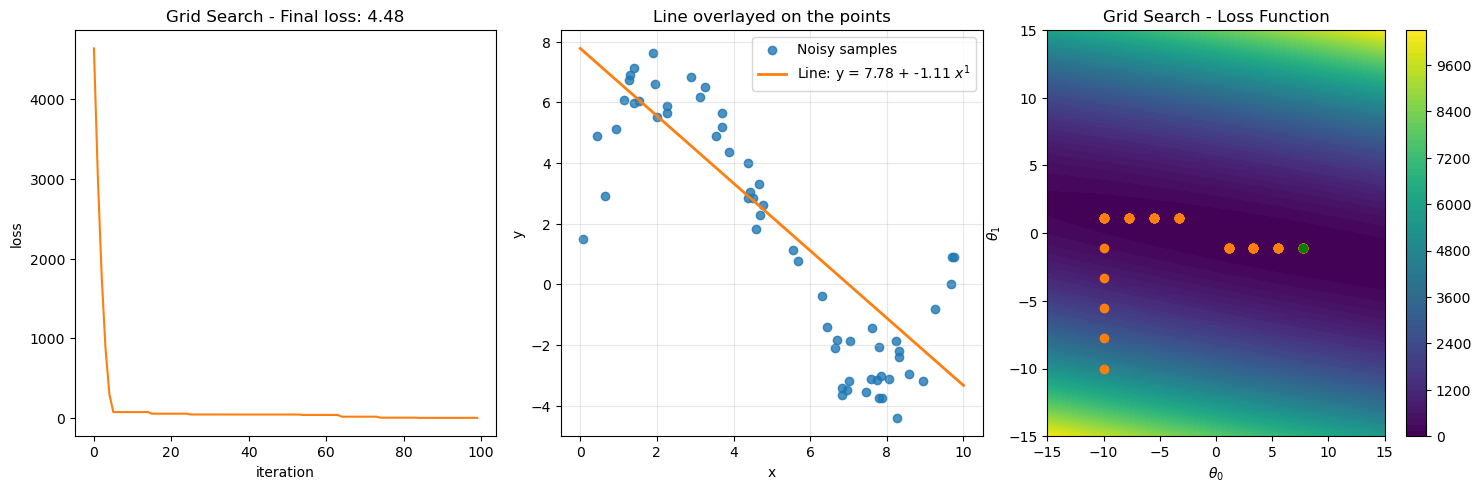

In [15]:
np.random.seed(42)
theta, best_loss, history_gs = grid_search(x,y, linear_model, mse_loss, 10)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.tight_layout()
plt.plot( range(len(history_gs)), [history_gs[c][1] for c in range(len(history_gs))], color='C1' )
plt.title( f"Grid Search - Final loss: {best_loss:.2f}" )
plt.xlabel('iteration')
plt.ylabel('loss')

plt.subplot(1, 3, 2)
plt.tight_layout()
plot_line(theta, plt.gca())

plt.subplot(1, 3, 3)
plt.tight_layout()
plt.contourf( np.linspace(-15, 15, 100), np.linspace(-15, 15, 100), 
              np.array([ [mse_loss(y, linear_model(x, [a,b])) for a in np.linspace(-15, 15, 100)] for b in np.linspace(-15, 15, 100) ]), levels=100 )
plt.colorbar()
plt.plot([h[0][0] for h in history_gs], [h[0][1] for h in history_gs], "o", color='C1', label="Best solution")

plt.plot(history_gs[-1][0][0], history_gs[-1][0][1], "go", label="Final solution")

plt.title('Grid Search - Loss Function')
plt.xlabel(r'$\theta_0$')
plt.ylabel(r'$\theta_1$')
plt.show()

In the first plot above, you should see a loss curve that only goes down and never up again, as the grid search only accepts a new hypothesis when it is better than the previous one, with long flat regions where the algorithm fails to guess a better solution. 

In [16]:
# This cell will do two increasingly strict tests for 2 marks
with tick.marks(1):
    assert best_loss < 10.0
with tick.marks(1):
    assert best_loss < 5.0


## Task 4 &mdash; Random Search &nbsp;*(3 marks with feedback)*

Next we will try the random search algorithm. It works as follows: 

- start with an initial guess for $\theta$
- generate a candidate set of parameter values $\theta'$
- check if $L(\mathbf{x},\mathbf{y},\theta') < L(\mathbf{x},\mathbf{y},\theta)$
- if yes, replace $\theta$ with $\theta'$
- return the best set of parameters after $T$ iterations

Below you are asked to implement the code for each iteration of the algorithm. 


In [17]:

# we define a function that guesses our line parameters (a,b) randomly in a reasonable range
def guess_line(): 
    return np.array([ (2.0*np.random.rand()-1.0)*10.0, (np.random.rand()-0.5)*10.0 ])

def random_search( x, y, model, loss, guess, T):
    theta = guess()
    best_loss = loss(y, model(x, theta))
    history = [(theta,best_loss)]
    for t in range(T):
        candidate_theta = guess()
        candidate_loss = loss(y, model(x, candidate_theta))

        if candidate_loss < best_loss:
            theta = candidate_theta
            best_loss = candidate_loss
        history.append( (theta, best_loss) )
    return theta, best_loss, history

In [18]:
np.random.seed(42)
theta, best_loss, history = grid_search(x,y, linear_model, mse_loss, 10)
with tick.marks(1):
    for i in range(len(history)-1):
        assert history[i][1] >= history[i+1][1] # check that the loss is decreasing 

You can test your implementation on the data by running the cell below: 

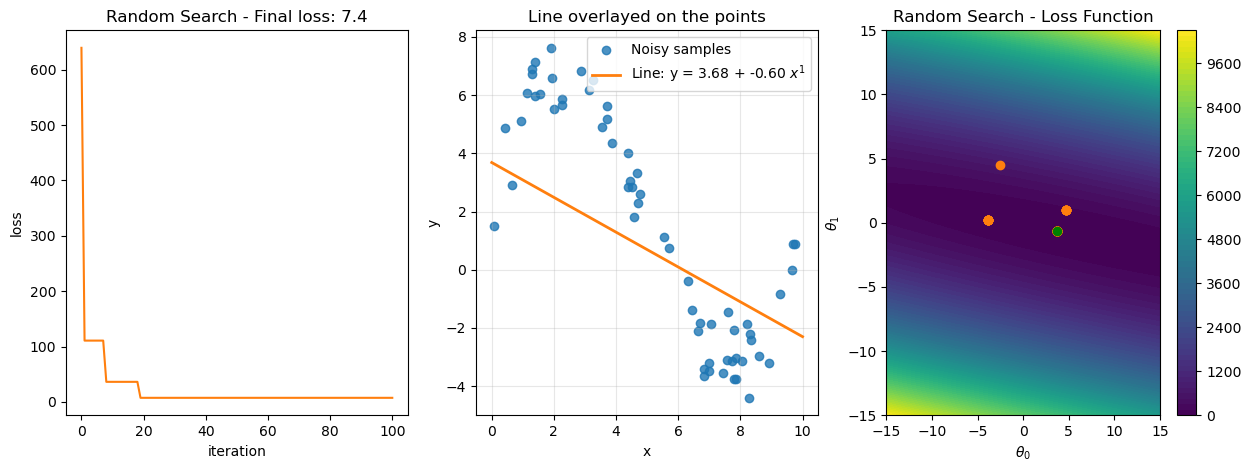

In [19]:
np.random.seed(42)

theta, best_loss, history_rs = random_search(x, y, linear_model, mse_loss, guess_line, 100)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.plot( range(len(history_rs)), [history_rs[c][1] for c in range(len(history_rs))], color='C1' )
plt.title( f"Random Search - Final loss: {best_loss:.2}" )
plt.xlabel('iteration')
plt.ylabel('loss')

plt.subplot(1, 3, 2)
plot_line(theta, plt.gca())

plt.subplot(1, 3, 3)
plt.contourf( np.linspace(-15, 15, 100), np.linspace(-15, 15, 100), 
              np.array([ [mse_loss(y, linear_model(x, [a,b])) for a in np.linspace(-15, 15, 100)] for b in np.linspace(-15, 15, 100) ]), levels=100 )
plt.colorbar()
plt.plot([h[0][0] for h in history_rs], [h[0][1] for h in history_rs], "o", color='C1', label="Best solution")

plt.plot(history_rs[-1][0][0], history_rs[-1][0][1], "go", label="Final solution")

plt.title('Random Search - Loss Function')
plt.xlabel(r'$\theta_0$')
plt.ylabel(r'$\theta_1$')
plt.show()

As before, the curve should be going down only, but with fewer flat regions: There will be cases where increasing gradually one parameter will keep on decreasing loss until the best value is reached. 

In [20]:
# This cell will do two increasingly strict tests for 2 marks
with tick.marks(1):
    assert best_loss < 10.0
with tick.marks(1):
    assert best_loss < 8.0

## Task 5 &mdash; Hill Climbing &nbsp;*(3 marks with feedback)*

The issue with grid search is that if the best solution is between two grid corners, the algorithm can only return the closest point on the grid. Additionally, there is a lot of wasted time on parts of the grid that are not good. 

To improve on this, we need to add some information to the search. We will make use of the *Heuristic of proximity* in the next algorithm: 
the idea that if a solution is good, another solution with similar parameters is likely to be good too, or even better. 

An example of an algorithm using this Heuristic is *Hill Climbing*, that we will implement next.

The Stochastic Hill Climbing algorithm works as follows: 

- Make an initial guess at the parameter values, like for random search
- apply a random *local* adjustment to the parameter vector: in other words, make a random guess at a set of parameters $\theta'$ *within a small region* around the current solution.  
- as before, check if $L(\mathbf{x},\mathbf{y},\theta') < L(\mathbf{x},\mathbf{y},\theta)$, where $\theta$ is the current best parameter set.  
- if yes, replace $\theta$ with $\theta'$
- return the best solution $\theta$ after $T$ iterations. 


First we need to define the neighbour function. This function takes as input a parameter vector $\theta$ and returns another parameter vector $\theta'$ that is *not too far*. 

We will define *not to far* as less than 1.0 unit distance for $\theta_0 and less than 0.5 units for $\theta_1$

You should use the Numpy function `np.random.rand()` to generate random numbers between 0 and 1 (as we did before for the guess function)

In [21]:
def neighbour(theta): 
    return [ 
        theta[0] + (np.random.rand() - 0.5) * 2.0,
        theta[1] + (np.random.rand() - 0.5) * 1.0
        ]

In [22]:
np.random.seed(42)
with tick.marks(1): 
    t2 = np.abs(neighbour([0,0]))
    assert t2[0] < 1.1
    assert t2[1] < 0.6

In [23]:
def hill_climbing(x, y, model, loss, guess, neighbour, T): 
    theta = guess()
    best_loss = loss(y, model(x, theta))
    history = [(theta,best_loss)]
    for t in range(T):
        candidate_theta = neighbour(theta)
        candidate_loss = loss(y, model(x, candidate_theta))

        if candidate_loss < best_loss:
            theta = candidate_theta
            best_loss = candidate_loss
        history.append( (theta, best_loss) )
    return theta, best_loss, history
    

In [24]:
np.random.seed(42)
theta, best_loss, history = hill_climbing(x,y, linear_model, mse_loss, guess_line, neighbour, 10)
with tick.marks(1):
    for i in range(len(history)-1):
        assert history[i][1] >= history[i+1][1] # check that the loss is decreasing 
        assert abs(history[i][0][0] - history[i+1][0][0]) < 1.1 # check that each jump is within the range of the neighbour function
        assert np.abs(history[i][0][1] - history[i+1][0][1]) < 0.6

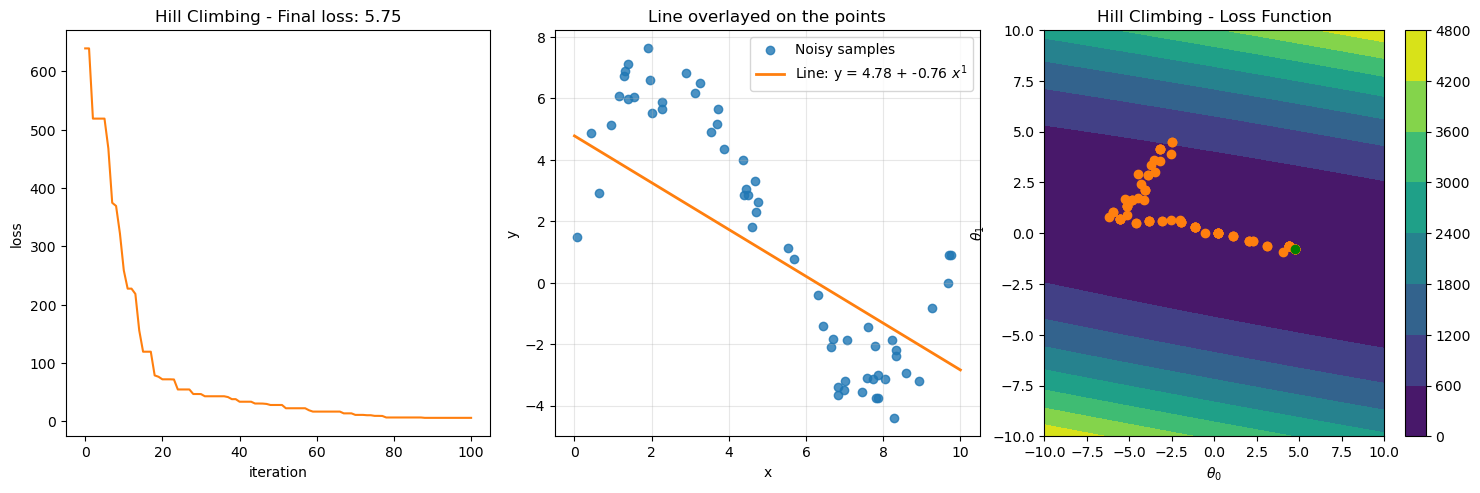

In [25]:
np.random.seed(42)
theta, best_loss, history_hc = hill_climbing(x, y, linear_model, mse_loss, guess_line, neighbour, 100)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.tight_layout()
plt.plot( range(len(history_hc)), [history_hc[c][1] for c in range(len(history_hc))], color='C1' )
plt.title( f"Hill Climbing - Final loss: {best_loss:.2f}" )
plt.xlabel('iteration')
plt.ylabel('loss')

plt.subplot(1, 3, 2)
plt.tight_layout()
plot_line(theta, plt.gca())

plt.subplot(1, 3, 3)
plt.tight_layout()
plt.contourf( np.linspace(-10, 10, 100), np.linspace(-10, 10, 100), 
              np.array([ [mse_loss(y, linear_model(x, [a,b])) for a in np.linspace(-10, 10, 100)] for b in np.linspace(-10, 10, 100) ]) )
plt.colorbar()
plt.plot([h[0][0] for h in history_hc], [h[0][1] for h in history_hc], "o", color='C1', label="Best solution")

plt.plot(history_hc[-1][0][0], history_hc[-1][0][1], "go", label="Final solution")

plt.title('Hill Climbing - Loss Function')
plt.xlabel(r'$\theta_0$')
plt.ylabel(r'$\theta_1$')

plt.show()


In [26]:
# The following tests will check how good is the resulting solution
# you can experiment with your neighbour function to improve your result
# I RECOMMEND NOT TO WASTE TOO LONG ON THIS IF TIME IS SHORT! 
# move on to Task 6 and come back to it if you have time. 


with tick.marks(1):
    assert best_loss < 20.0
with tick.marks(1):
    assert best_loss < 15.0
with tick.marks(1):
    assert best_loss < 10.0


We can also compare our trajectories for all three algorithms: 

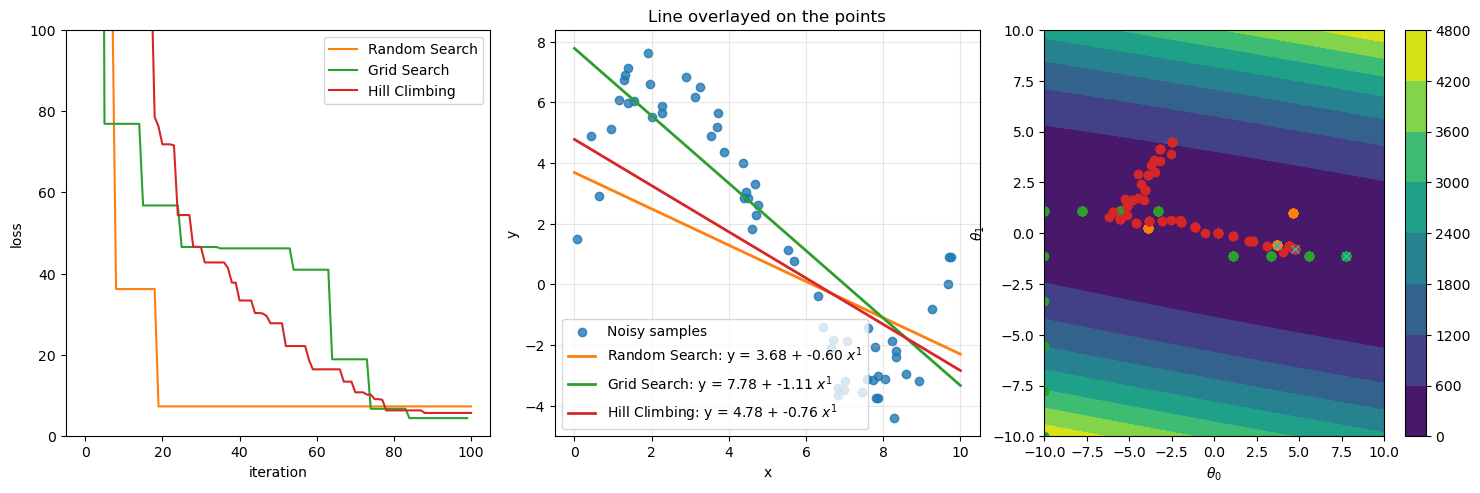

In [27]:
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.tight_layout()
plt.plot( range(len(history_rs)), [history_rs[c][1] for c in range(len(history_rs))], '-', color='C1', label="Random Search" )
plt.plot( range(len(history_gs)), [history_gs[c][1] for c in range(len(history_gs))], '-', color='C2', label="Grid Search" )
plt.plot( range(len(history_hc)), [history_hc[c][1] for c in range(len(history_hc))], '-', color='C3', label="Hill Climbing" )
plt.ylim(0, 100)
plt.xlabel('iteration')
plt.ylabel('loss')
plt.legend()

plt.subplot(1, 3, 2)
plt.tight_layout()
plot_line(history_rs[-1][0], plt.gca(), label="Random Search", color="C1")
plot_line(history_gs[-1][0], plt.gca(), label="Grid Search", color="C2", samples=False)
plot_line(history_hc[-1][0], plt.gca(), label="Hill Climbing", color="C3", samples=False)

plt.subplot(1, 3, 3)
plt.tight_layout()
plt.contourf( np.linspace(-10, 10, 100), np.linspace(-10, 10, 100), 
              np.array([ [mse_loss(y, linear_model(x, [a,b])) for a in np.linspace(-10, 10, 100)] for b in np.linspace(-10, 10, 100) ]) )
plt.colorbar()
plt.plot([h[0][0] for h in history_rs], [h[0][1] for h in history_rs], "o", color='C1', label="Random Search")
plt.plot([h[0][0] for h in history_gs], [h[0][1] for h in history_gs], "o", color='C2', label="Grid Search")
plt.plot([h[0][0] for h in history_hc], [h[0][1] for h in history_hc], "o", color='C3', label="Hill Climbing")

plt.plot(history_rs[-1][0][0], history_rs[-1][0][1], "x", color='C9', label="Random Search Final solution")
plt.plot(history_gs[-1][0][0], history_gs[-1][0][1], "x", color='C9', label="Grid Search Final solution")
plt.plot(history_hc[-1][0][0], history_hc[-1][0][1], "x", color='C9', label="Hill Climbing Final solution")

plt.xlabel(r'$\theta_0$')
plt.ylabel(r'$\theta_1$')
plt.show()

## Task 6 &mdash; Finding a better fit: Polynomial &nbsp;*(2 marks with feedback + 2 marks hidden)*

The three algorithms we tried before did their best, but looking closely at the data points, it seems clear that a 
line cannot model them accurately. 

In this task, we will run the models we coded before using a different parametrisation: A polynomial. 

A polynomial of degree $d$ is defined by the following equation 

$$
y = \sum_{i=0}^d \theta_i x^i
$$

where the parameters are $\mathbf{\theta} = \left(\theta_0, \ldots, \theta_d \right)$. 

For example, the line equation we used before is a polynomial of degree 1: 

$$
y = \theta_1 x + \theta_0
$$

and a polynomial of degree 3 would be 

$$
y = \theta_3 x^3 + \theta_2 x^2 + \theta_1 x + \theta_0
$$



You are given a guess function for creating random parameters. 

In [28]:
# new function for guessing the initial poly 
def guess_poly(order = 3): 
    return np.array([ (np.random.rand()-0.5)*1.0 for i in range(order + 1) ])

### Task 6.a Polynomial model

First, propose a new model function for our polynomials:

In [29]:
# we define our polynomial model
def poly_model(x, theta): 
    y_pred = np.zeros_like(x, dtype=float)

    for i in range(len(theta)):
        y_pred += theta[i] * x**i

    return y_pred

The test below should pass if your polynomial function is correct. 

In [30]:
with tick.marks(1):
    assert poly_model(2, [1, 10, 100, 1000]) == 8421

### Task 6.b Polynomial neighbour function

Second, you need to write a new neighbour function for the polynomials. It is recommended that: 

- use the function `np.random.rand()` to get uniform random numbers as we used before. 
- you move each parameter no more than 1.0 in value
- you move the paramter less when they are multiplied by a higher power, eg, for $y = \theta_2 x^2 + \theta_1 x^1 + x^0$, the neighbourhood for $\theta_2$ should be smaller than for $\theta_1$, itself smaller than $\theta_0$
- I recommend to use $0.1^n$ as a max displacement for $\theta_n$
- do not set the seed in this function, it will be set at the start of the algorithm. 

In [31]:

def poly_neighbour(theta): 
    # we're going to move the coefficients of the polynomial by a decreasing amount 
    # as the order increases, so that we don't change the higher order coefficients 
    # too much.

    new_theta = np.array(theta).copy()

    for i in range(len(theta)):
        displacement = (np.random.rand() - 0.5) * 2.0 * (0.1 ** i)
        new_theta[i] += displacement

    return new_theta

In [32]:
with tick.marks(1):
    assert np.max(np.abs(poly_neighbour([0,0,0,0]))) < 1.0

Finally we can run the Hill-climbing and random search algorithms with the new polynomial model. You should not modify this cell, if you coded the two functions as described earlier it should run. 

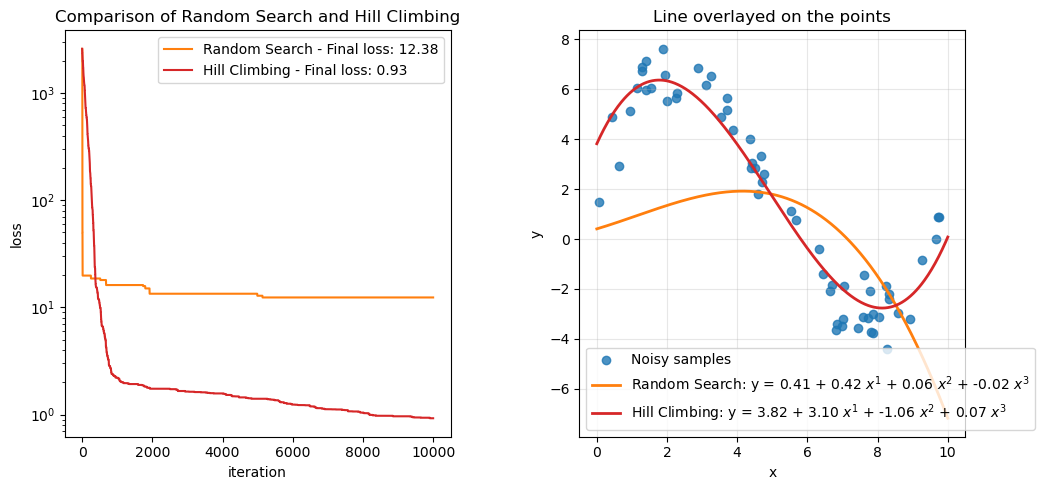

In [33]:
# This code will run the random search and hill climbing algorithms on the polynomial model and plot the results.
# you do not need to fully understand it. 

N = 10000

np.random.seed(42)
theta_poly_rs, best_loss_poly_rs, history_poly_rs = random_search(x,y, poly_model, mse_loss, guess_poly, N)

np.random.seed(42)
theta_poly_hc, best_loss_poly_hc, history_polyhc = hill_climbing(x,y, poly_model, mse_loss, guess_poly, poly_neighbour, N)

plt.figure(figsize=(15, 5))

# first we plot the loss of the two methods 
plt.subplot(1, 3, 1)
# we plot on a log scale the loss of the two methods to improve readability of the graph
plt.semilogy( range(len(history_poly_rs)), [history_poly_rs[c][1] for c in range(len(history_poly_rs))], 'C1', label=f'Random Search - Final loss: {best_loss_poly_rs:.2f}' )
plt.semilogy( range(len(history_polyhc)), [history_polyhc[c][1] for c in range(len(history_polyhc))], 'C3', label=f'Hill Climbing - Final loss: {best_loss_poly_hc:.2f}' )
plt.title( f"Comparison of Random Search and Hill Climbing" )
plt.xlabel('iteration')
plt.ylabel('loss')
plt.legend()

# Second, we plot the best polynomial found by each method
plt.subplot(1, 3, 2)
plot_line(theta_poly_rs, plt.gca(), model=poly_model, label="Random Search", color="C1", samples=True)
plot_line(theta_poly_hc, plt.gca(), model=poly_model, label="Hill Climbing", color="C3", samples=False)
plt.tight_layout()

plt.show()

In [34]:
# Two visible tests to check whether the algorithms have converged

with tick.marks(1):
    assert best_loss_poly_rs < 20.0
with tick.marks(1):
    assert best_loss_poly_hc < 20.0

In [35]:
# ... and two more hidden tests will check how close to the solution you are. 


---
## Before you finish

1. **Kernel &rarr; Restart Kernel and Run All Cells.** The notebook must run top to bottom with no errors (no red boxes, no tracebacks).
2. Check the **marks summary** below.
3. Upload the completed `.ipynb` to Moodle. 



# Appendix: Marks summary

Run **Kernel &rarr; Restart Kernel and Run All Cells** before reading this, or it will be out of date.


In [36]:
print("Marks available: 20  (visible with feedback: 14,  hidden: 6)")

# tick.summarise_marks() only reads the id-based tick.Marks() records, which this
# lab does not use; summarise from the counters tick.marks() maintains instead.
import IPython.display
if tick.available_marks > 0:
    IPython.display.display(IPython.display.HTML(
        """<!--{id:"TOTALMARK",marks:"%d", available:"%d"}  -->
        <div class="alert alert-box alert-success">
        <h1> Marks in this run: %d/%d (%.1f%%) </h1> </div>"""
        % (tick.total_marks, tick.available_marks,
           tick.total_marks, tick.available_marks,
           tick.total_marks / tick.available_marks * 100)))
else:
    print("No marks recorded -- use Kernel -> Restart Kernel and Run All Cells.")


Marks available: 20  (visible with feedback: 14,  hidden: 6)
